# Do discounts and delivery performance help or hurt the business?

**Stage 3 of the pipeline - pandas analysis.** *The data is simulated* (a synthetic e-commerce dataset with
138k orders, 2021-2025), so the findings show the method rather than describing a real company.

**The three questions**
1. At what discount level does a sale stop making money, and does extra volume make up for it?
2. Which product categories sell a lot but earn little?
3. Does slower delivery lead to lower customer ratings?

The SQL in `sql/02_analysis_queries.sql` answers the same questions. This notebook repeats the work in pandas,
adds charts, and checks that both tools give the same numbers.

## 0. Setup

We load the libraries and set one chart style for the whole notebook: blue for the main data, red only for losses or
late deliveries, and grey for context. Every chart is also saved to `images/` so the README and write-up can show it.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path("..")
RAW = ROOT / "data" / "raw"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

BLUE, RED, ORANGE, GREY, INK, MUTED = "#2a78d6", "#e34948", "#eb6834", "#b4b2ab", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "text.color": INK, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and clean the data

We load the four linked tables and apply the decisions from the data quality report (`reports/data_quality_report.md`):

* **Money comes from `order_items`.** About 8% of order headers don't match their own line items.
* **Profit is recalculated** as `gross_sales - discount_amount - product_cost`. The supplied profit column counts sales
  tax as income, and tax belongs to the government.
* **Completed orders only.** Discounts were wiped on cancelled/returned lines, and only completed orders have a delivery
  time and a rating.
* `discount_percentage` is already a 0-1 fraction (0.25 = 25% off). We only multiply by 100 for labels.

The join attaches each line's order status (from `orders`) and its category and list price (from `product_catalog`),
just like the SQL view `v_completed_lines`.

In [2]:
orders = pd.read_csv(RAW / "orders.csv")
items = pd.read_csv(RAW / "order_items.csv")
products = pd.read_csv(RAW / "product_catalog.csv")

lines = (items
         .merge(orders[["order_id", "order_status"]], on="order_id", how="inner")
         .merge(products[["product_id", "product_category", "unit_price", "product_cost"]]
                .rename(columns={"unit_price": "list_price", "product_cost": "unit_cost"}),
                on="product_id", how="inner"))
lines = lines[lines["order_status"] == "Completed"].copy()

lines["revenue"] = lines["gross_sales"] - lines["discount_amount"]
lines["profit_before_tax"] = lines["revenue"] - lines["product_cost"]
lines["list_margin"] = (lines["list_price"] - lines["unit_cost"]) / lines["list_price"]

BAND_LABELS = ["0%", "1-10%", "11-20%", "21-30%", "31-40%", "41-50%", "51-60%"]
lines["discount_band"] = pd.cut(lines["discount_percentage"],
                                bins=[-0.001, 0, .10, .20, .30, .40, .50, .60], labels=BAND_LABELS)

print(f"{len(lines):,} completed order lines across {lines['order_id'].nunique():,} orders")
lines[["order_id", "product_category", "quantity", "discount_percentage", "revenue", "profit_before_tax", "discount_band"]].head()

327,028 completed order lines across 113,559 orders


,order_id,product_category,quantity,discount_percentage,revenue,profit_before_tax,discount_band
0,ORD-301242,Health & Wellness,2,0.34,322.80,149.52,31-40%
1,ORD-301242,Fashion,3,0.36,549.50,134.45,31-40%
2,ORD-773460,Jewelry,4,0.47,"1,605.31",-370.85,41-50%
3,ORD-773460,Beauty & Personal Care,4,0.34,83.27,27.55,31-40%
4,ORD-449374,Grocery,3,0.09,17.23,11.32,1-10%


## 2. Q1 - At what discount level does a sale stop making money?

**Approach.** Group every completed line into 10-point discount bands and compare, for each band: profit margin
(profit ÷ revenue), profit per line, and the share of lines that lost money.

In [3]:
q1 = (lines.groupby("discount_band", observed=True)
      .agg(lines=("order_id", "size"), units=("quantity", "sum"), units_per_line=("quantity", "mean"),
           revenue=("revenue", "sum"), profit=("profit_before_tax", "sum"),
           loss_share=("profit_before_tax", lambda s: (s < 0).mean())))
q1["margin"] = q1["profit"] / q1["revenue"]
q1["profit_per_line"] = q1["profit"] / q1["lines"]
q1

,lines,units,units_per_line,revenue,profit,loss_share,margin,profit_per_line
discount_band,,,,,,,,
0%,3441,6511,1.89,"1,583,698.86","766,245.23",0.00,0.48,222.68
1-10%,107520,202701,1.89,"47,326,161.44","21,524,412.16",0.00,0.45,200.19
11-20%,123795,232755,1.88,"48,181,220.94","18,958,875.33",0.00,0.39,153.15
21-30%,46493,110211,2.37,"20,373,124.40","6,427,446.96",0.00,0.32,138.25
31-40%,21740,71833,3.30,"11,533,563.60","2,461,636.97",0.04,0.21,113.23
41-50%,17062,56710,3.32,"7,696,822.47","524,265.69",0.22,0.07,30.73
51-60%,6977,23023,3.30,"2,399,623.95","-451,191.78",0.61,-0.19,-64.67


**Pinning down the break-even.** 10-point bands are coarse, so we repeat the grouping with 5-point bands to find where
the *average* sale crosses zero.

In [4]:
fine = lines.assign(band_start=(lines["discount_percentage"] * 20).astype(int) * 5)
q1_fine = fine.groupby("band_start").agg(lines=("order_id", "size"), revenue=("revenue", "sum"),
                                         profit=("profit_before_tax", "sum"),
                                         loss_share=("profit_before_tax", lambda s: (s < 0).mean()))
q1_fine["margin"] = q1_fine["profit"] / q1_fine["revenue"]
q1_fine[["lines", "margin", "loss_share"]]

,lines,margin,loss_share
band_start,,,
0,50108,0.47,0.00
5,60853,0.44,0.00
10,61762,0.41,0.00
15,62033,0.38,0.00
20,30574,0.33,0.00
25,15919,0.29,0.00
30,12574,0.24,0.02
35,9166,0.17,0.08
40,8992,0.11,0.16


**Why sales flip to a loss.** A line has to lose money once its discount is bigger than the product's own margin
(price minus cost, as a share of price). A product with a 40% margin breaks even at 40% off. The test below checks that
this rule explains every loss in the data.

In [5]:
rule = pd.crosstab(lines["discount_percentage"] > lines["list_margin"], lines["profit_before_tax"] < 0,
                   rownames=["discount > product margin"], colnames=["line lost money"])
print(rule)
print(f"\nAverage product margin: {lines['list_margin'].mean():.0%}  "
      f"(range {lines['list_margin'].min():.0%}-{lines['list_margin'].max():.0%})")

line lost money             False  True 
discount > product margin               
False                      318112      0
True                            0   8916

Average product margin: 53%  (range 30%-75%)


## 3. Q1 (continued) - Does extra volume make up for it?

Heavier discounts do come with bigger baskets (more units per line). The question is whether those extra units make up
for the lower profit on each unit.

**Approach.** Use the light 1-10% discount as the baseline. For each band, compare:
* **units needed** - how many times more units a line would have to sell to match the baseline's profit per line
* **units actually sold** - how many times more units it really sells

In [6]:
base = q1.loc["1-10%"]
vol = pd.DataFrame({
    "profit_per_unit": q1["profit"] / q1["units"],
    "units_actual_x": q1["units_per_line"] / base["units_per_line"],
})
vol["units_needed_x"] = np.where(vol["profit_per_unit"] > 0,
                                 (base["profit"] / base["units"]) / vol["profit_per_unit"], np.nan)
vol["profit_per_line_vs_base"] = q1["profit_per_line"] / base["profit_per_line"]
vol

,profit_per_unit,units_actual_x,units_needed_x,profit_per_line_vs_base
discount_band,,,,
0%,117.68,1.00,0.90,1.11
1-10%,106.19,1.00,1.00,1.00
11-20%,81.45,1.00,1.30,0.77
21-30%,58.32,1.26,1.82,0.69
31-40%,34.27,1.75,3.10,0.57
41-50%,9.24,1.76,11.49,0.15
51-60%,-19.60,1.75,NaN,-0.32


**Chart 1.** Left: profit margin falls steadily as discounts deepen and turns negative above 50%.
Right: profit per line compared with the 1-10% baseline. The extra volume never closes the gap.

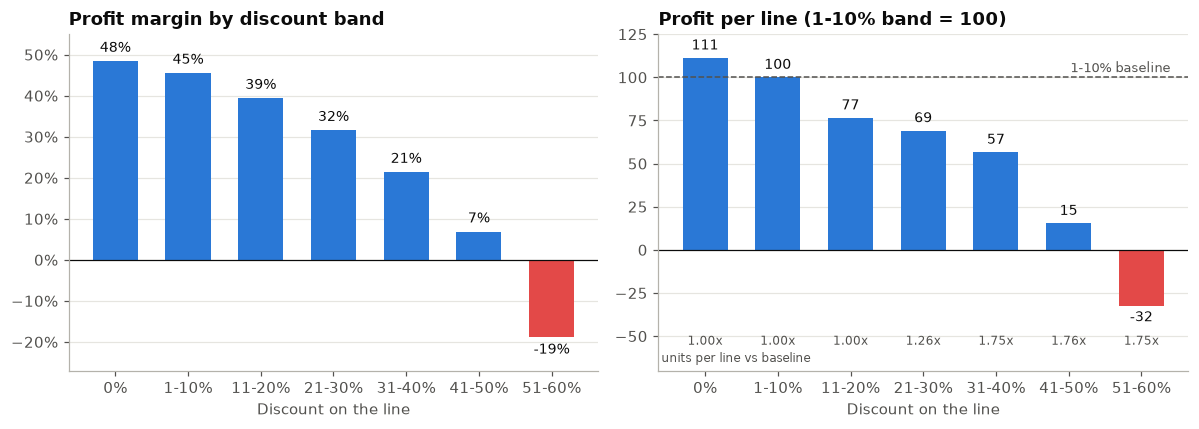

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(q1))

colors = [RED if m < 0 else BLUE for m in q1["margin"]]
ax1.bar(x, q1["margin"] * 100, color=colors, width=0.62)
ax1.axhline(0, color=INK, lw=0.8)
for xi, m in zip(x, q1["margin"]):
    ax1.text(xi, m * 100 + (1.5 if m >= 0 else -1.5), f"{m:.0%}", ha="center", va="bottom" if m >= 0 else "top", fontsize=9, color=INK)
ax1.set_ylim(-27, 55)
ax1.set_xticks(x, q1.index)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.set_title("Profit margin by discount band")
ax1.set_xlabel("Discount on the line")

ppl = vol["profit_per_line_vs_base"] * 100
ax2.bar(x, ppl, color=[RED if v < 0 else BLUE for v in ppl], width=0.62)
ax2.axhline(100, color=MUTED, lw=1, ls="--")
ax2.text(len(x) - 0.6, 103, "1-10% baseline", ha="right", fontsize=8.5, color=MUTED)
ax2.axhline(0, color=INK, lw=0.8)
for xi, v, u in zip(x, ppl, vol["units_actual_x"]):
    ax2.text(xi, v + (3 if v >= 0 else -3), f"{v:.0f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, color=INK)
    ax2.text(xi, -55, f"{u:.2f}x", ha="center", fontsize=8, color=MUTED)
ax2.text(-0.6, -65, "units per line vs baseline", fontsize=8, color=MUTED)
ax2.set_ylim(-70, 125)
ax2.set_xticks(x, q1.index)
ax2.set_title("Profit per line (1-10% band = 100)")
ax2.set_xlabel("Discount on the line")

fig.tight_layout()
fig.savefig(IMAGES / "q1_discount_profitability.png")
plt.show()

**Q1 answer.** The average sale stays profitable up to about **45-50% off** and loses money beyond that. Individual
lines start losing from about **30% off**, as soon as the discount is bigger than that product's margin. Deep discounts
(31%+) do sell about **1.75x the units** per line, but at 41-50% off a line would need about **11x** the units to match a
lightly discounted line. **The extra volume does not make up for it.**

## 4. Q2 - Which product categories sell a lot but earn little?

**Approach.** For each category, measure volume (units sold) and earnings (profit margin, plus profit per unit as a
second view). A category is "high volume, low margin" if it sells more units than the average category but earns a
lower margin than the average category.

In [8]:
q2 = (lines.groupby("product_category")
      .agg(units=("quantity", "sum"), gross=("gross_sales", "sum"), discount=("discount_amount", "sum"),
           cost=("product_cost", "sum"), revenue=("revenue", "sum"), profit=("profit_before_tax", "sum")))
q2["margin"] = q2["profit"] / q2["revenue"]
q2["profit_per_unit"] = q2["profit"] / q2["units"]
q2["list_margin"] = 1 - q2["cost"] / q2["gross"]          # margin before discounts
q2["avg_discount"] = q2["discount"] / q2["gross"]

hi_vol = q2["units"] >= q2["units"].mean()
lo_margin = q2["margin"] < q2["margin"].mean()
q2["quadrant"] = np.select([hi_vol & lo_margin, hi_vol, lo_margin],
                           ["High volume, low margin", "High volume, healthy margin", "Low volume, low margin"],
                           "Low volume, healthy margin")
q2.sort_values("units", ascending=False)[["units", "margin", "profit_per_unit", "list_margin", "avg_discount", "quadrant"]]

,units,margin,profit_per_unit,list_margin,avg_discount,quadrant
product_category,,,,,,
Sports & Outdoors,54005,0.39,83.02,0.51,0.19,"High volume, low margin"
Books & Media,51883,0.51,18.70,0.60,0.19,"High volume, healthy margin"
Health & Wellness,51829,0.40,51.37,0.52,0.19,"High volume, low margin"
Beauty & Personal Care,49974,0.49,32.45,0.59,0.19,"High volume, healthy margin"
Automotive,48280,0.32,78.27,0.45,0.19,"High volume, low margin"
Office Supplies,48019,0.47,61.81,0.57,0.19,"High volume, healthy margin"
Home Appliances,47094,0.34,130.65,0.47,0.20,"High volume, low margin"
Toys & Games,46651,0.47,39.11,0.57,0.19,"Low volume, healthy margin"
Grocery,46634,0.54,23.66,0.63,0.19,"Low volume, healthy margin"


**Is it the discount or the product cost?** Every category gets almost the same average discount (about 19%), so
discounting doesn't explain why some categories earn less. The gap comes from **list margin**: what the product costs
compared with its price, before any discount.

In [9]:
print(f"Average discount by category ranges only {q2['avg_discount'].min():.1%} - {q2['avg_discount'].max():.1%}")
print(f"Correlation of earned margin with list margin: {q2['margin'].corr(q2['list_margin']):.2f}")
print(f"Correlation of earned margin with avg discount: {q2['margin'].corr(q2['avg_discount']):.2f}")

Average discount by category ranges only 19.1% - 19.6%
Correlation of earned margin with list margin: 1.00
Correlation of earned margin with avg discount: 0.16


**Chart 2.** Each dot is a category. The dashed lines are the averages, which split the chart into four quadrants.
The orange dots in the bottom-right (high volume, low margin) are the problem categories.

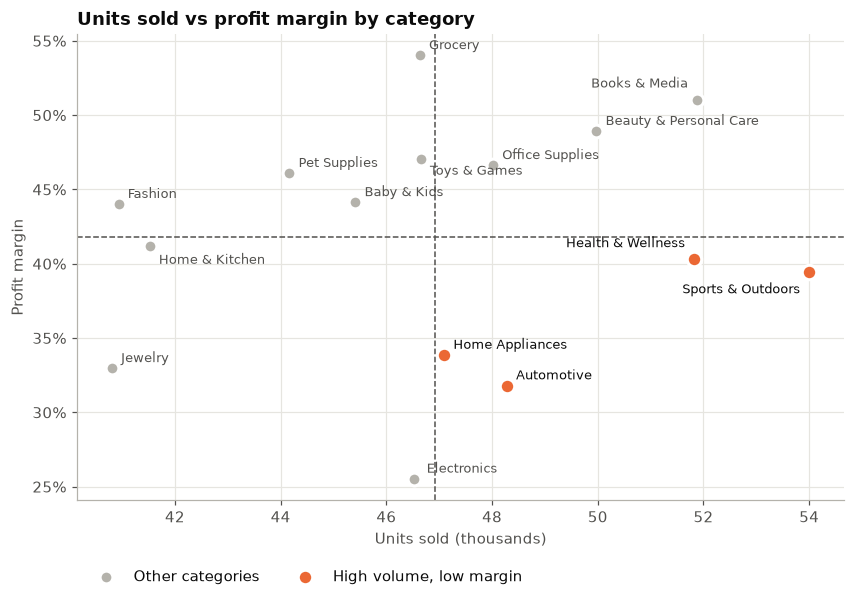

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
flag = q2["quadrant"] == "High volume, low margin"
ax.scatter(q2.loc[~flag, "units"] / 1000, q2.loc[~flag, "margin"] * 100, s=70, color=GREY,
           edgecolor="white", linewidth=2, zorder=3, label="Other categories")
ax.scatter(q2.loc[flag, "units"] / 1000, q2.loc[flag, "margin"] * 100, s=90, color=ORANGE,
           edgecolor="white", linewidth=2, zorder=4, label="High volume, low margin")
ax.axvline(q2["units"].mean() / 1000, color=MUTED, ls="--", lw=1)
ax.axhline(q2["margin"].mean() * 100, color=MUTED, ls="--", lw=1)
offsets = {"Health & Wellness": (-6, 8), "Sports & Outdoors": (-6, -14), "Home & Kitchen": (6, -12), "Electronics": (8, 4), "Books & Media": (-6, 8),
           "Beauty & Personal Care": (6, 4), "Toys & Games": (6, -10), "Grocery": (6, 4)}
for name, r in q2.iterrows():
    dx, dy = offsets.get(name, (6, 4))
    ax.annotate(name, (r["units"] / 1000, r["margin"] * 100), xytext=(dx, dy), textcoords="offset points",
                ha="right" if dx < 0 else "left", fontsize=8.5, color=INK if flag[name] else MUTED)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Units sold (thousands)")
ax.set_ylabel("Profit margin")
ax.set_title("Units sold vs profit margin by category")
ax.grid(axis="x", color="#e6e5e0", lw=0.8)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
fig.savefig(IMAGES / "q2_category_volume_vs_margin.png")
plt.show()

**Q2 answer.** **Sports & Outdoors** (the #1 seller), **Health & Wellness**, **Automotive** and **Home Appliances** sell
more than average but earn below-average margins (32-40%, compared with 51-54% for Books and Grocery). Electronics has
the thinnest margin of all (26%) but only average volume. The cause is **cost structure, not discounting**: every
category gets about a 19% average discount. A second reading: **Books & Media** is the #2 seller by units but makes only
about $19 profit per unit, so it is busy but small-ticket.

*Caveat:* category volumes in this simulated data are fairly even (41k-54k units), so "high volume" here means
moderately above average.

## 5. Q3 - Does slower delivery lead to lower customer ratings?

**Approach.** Look at completed orders (the only ones with a rating) in three ways:
1. raw delivery time vs rating
2. delivery measured against the **promise**: days late = actual days - estimated days
3. a natural experiment: shipping methods with very different delivery times

In [11]:
done = orders[orders["order_status"] == "Completed"].copy()
done["days_late"] = done["delivery_days"] - done["estimated_delivery_days"]

by_days = done.groupby("delivery_days")["customer_rating"].agg(["mean", "size"])
by_late = done.groupby("days_late")["customer_rating"].agg(["mean", "size"])
by_status = done.groupby("delivery_status")["customer_rating"].agg(
    avg_rating="mean", orders="size", pct_below_3=lambda r: (r < 3).mean())
by_method = done.groupby("shipping_method").agg(avg_days=("delivery_days", "mean"),
                                                delayed=("delivery_status", lambda s: (s == "Delayed").mean()),
                                                avg_rating=("customer_rating", "mean"))
print("Correlation with rating:  delivery days", round(done["delivery_days"].corr(done["customer_rating"]), 2),
      "| days late", round(done["days_late"].corr(done["customer_rating"]), 2))
display(by_status.sort_values("avg_rating", ascending=False))
display(by_method.sort_values("avg_days"))

Correlation with rating:  delivery days -0.16 | days late -0.39


,avg_rating,orders,pct_below_3
delivery_status,,,
Early,4.02,9757,0.01
On Time,3.73,86916,0.04
Delayed,3.22,16886,0.27


,avg_days,delayed,avg_rating
shipping_method,,,
Same Day,0.82,0.14,3.68
Express,2.26,0.15,3.68
Standard,5.25,0.15,3.68
Economy,7.74,0.15,3.67


**Reading the results.** Raw delivery time shows only a weak link with ratings. Being late against the promise shows a
link more than twice as strong. The shipping-method table is the clearest evidence: Economy takes almost **10x longer
than Same Day**, yet both get the same 3.67-3.68 rating, because both are late on about 15% of orders. Customers rate
against the promise they were given, not the number of days.

**Chart 3.** Average rating by days late. Being even one day late drops ratings by half a star, and being 1 or 4 days
late makes no difference.

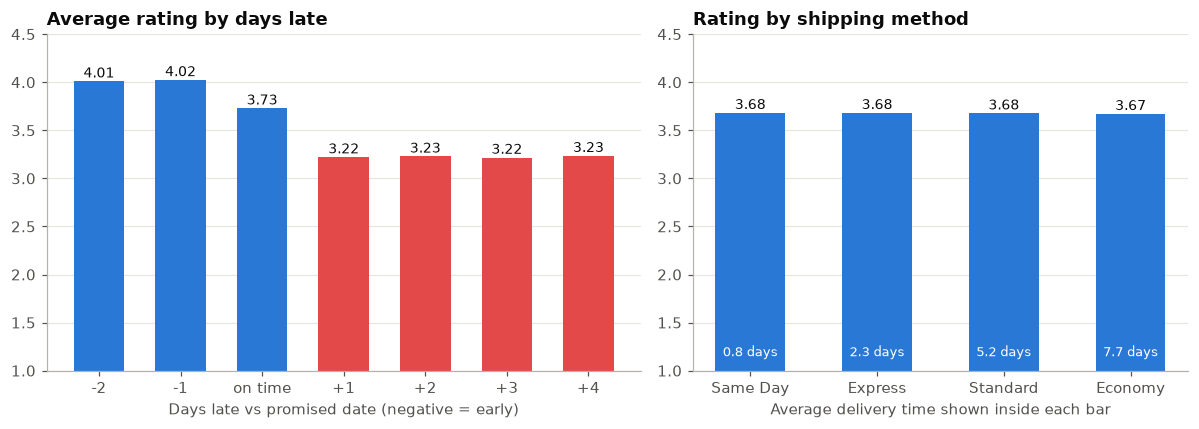

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.2, 1]})
lx = by_late.index.astype(int)
ax1.bar(lx, by_late["mean"], color=[RED if d > 0 else BLUE for d in lx], width=0.62)
for d, v in zip(lx, by_late["mean"]):
    ax1.text(d, v + 0.04, f"{v:.2f}", ha="center", fontsize=9)
ax1.set_ylim(1, 4.5)
ax1.set_xticks(lx, [("on time" if d == 0 else f"{d:+d}") for d in lx])
ax1.set_xlabel("Days late vs promised date (negative = early)")
ax1.set_title("Average rating by days late")

m = by_method.sort_values("avg_days")
ax2.bar(m.index, m["avg_rating"], color=BLUE, width=0.55)
for i, (name, r) in enumerate(m.iterrows()):
    ax2.text(i, r["avg_rating"] + 0.04, f"{r['avg_rating']:.2f}", ha="center", fontsize=9)
    ax2.text(i, 1.15, f"{r['avg_days']:.1f} days", ha="center", fontsize=8.5, color="white")
ax2.set_ylim(1, 4.5)
ax2.set_title("Rating by shipping method")
ax2.set_xlabel("Average delivery time shown inside each bar")
fig.tight_layout()
fig.savefig(IMAGES / "q3_delivery_vs_rating.png")
plt.show()

**Where do delays come from?** If one warehouse caused most delays, the fix would be local. Checking all 19 warehouses
shows a narrow 14-16% spread, so delays are spread evenly across the network. That points to how delivery dates are
promised, not to one bad site.

In [13]:
wh = done.groupby("warehouse")["delivery_status"].apply(lambda s: (s == "Delayed").mean())
print(f"Delay rate by warehouse: {wh.min():.1%} - {wh.max():.1%} (median {wh.median():.1%})")

Delay rate by warehouse: 14.1% - 15.8% (median 14.9%)


**Q3 answer.** **Not slower delivery as such - late delivery.** Delayed orders (15% of completed orders) average **3.22**
stars, compared with **3.73** for on-time and **4.02** for early. 26.5% of delayed orders are rated below 3, compared
with 3.8% of on-time orders. Total delivery time barely matters once you control for the promise.

## 6. Cross-check against SQL

Stage 2 saved the SQL results to `outputs/sql_results/`. If pandas and SQL agree, we can trust both.

In [14]:
sql_q1 = pd.read_csv(ROOT / "outputs" / "sql_results" / "q01_discount_band_summary.csv").set_index("discount_band")
sql_q9 = pd.read_csv(ROOT / "outputs" / "sql_results" / "q09_rating_by_delivery_status.csv").set_index("delivery_status")
check = pd.DataFrame({
    "q1 profit (pandas)": q1["profit"].round(0).values, "q1 profit (SQL)": sql_q1["profit"].values,
}, index=q1.index)
check["match"] = (check.iloc[:, 0] - check.iloc[:, 1]).abs() <= 1
display(check)
print("Q3 ratings match:", np.allclose(by_status["avg_rating"].round(2), sql_q9.loc[by_status.index, "avg_rating"]))

,q1 profit (pandas),q1 profit (SQL),match
discount_band,,,
0%,"766,245.00","766,245.00",True
1-10%,"21,524,412.00","21,524,412.00",True
11-20%,"18,958,875.00","18,958,875.00",True
21-30%,"6,427,447.00","6,427,447.00",True
31-40%,"2,461,637.00","2,461,637.00",True
41-50%,"524,266.00","524,266.00",True
51-60%,"-451,192.00","-451,192.00",True


Q3 ratings match: True


## 7. Summary

| Question | Finding | Recommendation |
|---|---|---|
| Q1 Discounts | Lines lose money once the discount is bigger than the product's margin (from about 30%); the average sale breaks even around 45-50%. Deep discounts sell 1.75x the units, but at 41-50% off they would need 11x. | Cap discounts per product at its margin minus a buffer; cap blanket promotions at about 30%. |
| Q2 Categories | Sports & Outdoors, Health & Wellness, Automotive and Home Appliances are high volume but low margin. The cause is cost structure, not discounts. | Review supplier costs and prices in those categories, and exclude them from deep promotions. |
| Q3 Delivery | Ratings fall when delivery is late against the promise (3.22 vs 3.73), not when delivery is slow. | Set delivery estimates with a buffer and track the on-time rate as a KPI. |

*Simulated data: these results demonstrate the method and shouldn't be read as facts about a real retailer.*